# 63 · 논문을 계산 명세와 작은 재현으로

📎 **이번 질문** · 논문의 한 주장을 어디까지 구현하고 무엇으로 확인했는지, 다른 사람도 다시 검사할 수 있을까요?

이 종합 단원은 빈 보고서 양식으로 끝내지 않습니다. [36 Flow Matching](../04_생성/36_flow_matching.ipynb)의 원논문 한 주장을 골라, Gaussian 자료·작은 선형 속도장·전체 미분·실제 학습·독립 평가까지 다시 완성합니다. 준비물은 11 최소제곱, 13 미분, 15 실험 설계, 27 적분과 표준오차, 36 속도 회귀입니다. NumPy·CPU float64만 사용하며 다른 노트북을 먼저 실행할 필요가 없습니다.

| 표시 | 읽을 것 |
|---|---|
| 🔑 | 주장·가정·shape·계산 |
| 🔍 | 독립 증거와 해석 |
| 📎 | 용어·코드·출처 |
| ✏️ | 직접 바꿀 핵심 식 |

**반드시 가져갈 세 가지:** ① 원논문의 주장과 이번 실험 범위를 분리합니다. ② 계산을 독립 경로로 검산하고 작은 완성 모델을 학습합니다. ③ 지표·그림·설정·실패 한계를 함께 남깁니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/paper_reproduction_plots.py)

In [1]:
# 준비 셀: 본문 계산과 별개의 시각화·중심차분 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.paper_reproduction_plots import (plot_scope_table,plot_specification,
    plot_independent_checks,plot_reproduction_plan,plot_reproduction_learning,
    plot_exact_paths,plot_paired_evidence,plot_paired_samples)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 논문의 주장과 재현할 범위를 먼저 고정합니다

**이 절에서 가져갈 것:** 논문의 결론 전체가 아니라 확인 가능한 한 계산을 선택합니다.

과일 자료의 분포까지 잡음 점을 옮기고 싶습니다. [Flow Matching 원문 3.2절·Theorem 2](https://arxiv.org/html/2210.02747v2#S3.SS2)는 조건부 속도 회귀와 주변 속도 회귀의 **기댓값 목적 기울기**가 같음을 설명합니다. 여기서는 이 관계를 독립 수치 적분으로 확인하고, 조건부 표본만으로 실제 속도장을 학습합니다.

| 구분 | 이번 계산 명세 |
|---|---|
| 원자료 | $y\sim N(1.2,.7^2)$, 출발 $x_0\sim N(0,1)$와 독립 |
| 경로 | $a(t)=1-.9t$, $x_t=a(t)x_0+ty$ |
| 타깃 | $u=y-.9x_0$, $t\sim U[0,1]$ |
| 이번 목표 | 조건부·주변 목적의 기울기, 실제 학습, 생성 경로 확인 |
| 범위 밖 | 원논문의 신경망·이미지 데이터·성능표 재현 |

> **용어** · **재현 범위(scope)**는 이번 구현이 뒷받침할 주장의 경계입니다. **계산 명세**는 입력·고정값·난수·출력·미분·갱신·평가를 미리 적은 약속입니다. **최소 잡음 σmin**은 조건부 경로 끝에 남기는 출발 잡음 비율입니다.

원문의 Gaussian 조건부 경로에 맞춰 σmin=.1을 둡니다. 따라서 끝점은 y가 아니라 $y+.1x_0$이며 **목표 분산은 .49+.01=.50**입니다. 36의 σmin=0 예제와 이 점이 다릅니다. 자료 분포와의 작은 차이까지 기록해야 실험 목표가 바뀐 사실을 놓치지 않습니다.

In [2]:
scope_values=np.array([[1.2,.49,np.sqrt(.49)],[1.2,.50,np.sqrt(.50)]])

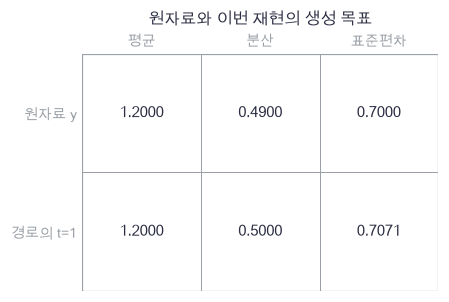

In [3]:
plot_scope_table(scope_values)

🔍 **확인** · 평균이 같아도 생성할 목표의 분산은 조금 더 큽니다. 이 차이는 학습 실패나 solver 오차가 아니라 선택한 경로의 정의입니다.

In [4]:
def make_pairs(n,seed,minimum=.1):
    """독립 x0~N(0,1), y~N(1.2,.7²), t~U[0,1]의 CFM 표본입니다."""
    rng=np.random.default_rng(seed)
    x0=rng.normal(size=n)
    y=1.2+.7*rng.normal(size=n)
    t=rng.uniform(size=n)
    a=1-(1-minimum)*t
    return a*x0+t*y,t,y-(1-minimum)*x0

In [5]:
example_x0=np.array([-1.,1.])
example_y=np.array([.5,1.9])
endpoint=.1*example_x0+example_y
np.testing.assert_allclose(endpoint,[.4,2.])  # 검산: t=1에도 출발 잡음 .1이 남음
sample_x,sample_t,sample_u=make_pairs(5,6300)
assert sample_x.shape==sample_t.shape==sample_u.shape==(5,), '관측 축5개를 공유해야 합니다'
assert np.all((0<=sample_t)&(sample_t<=1)), '학습 시간은0부터1 사이입니다'

### ✏️ 연습 1 · 경로 끝의 목표 분산

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

독립 자료 분산과 출발 잡음의 남은 분산을 합하세요.

In [6]:
def exercise_endpoint_variance(data_variance,minimum):
    """경로 끝의 목표 분산의 핵심 계산입니다."""
    ### 구현할 내용: 독립 자료 분산과 출발 잡음의 남은 분산을 합하세요.
    raise NotImplementedError
    return variance

In [7]:
def check_endpoint_variance(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(.49,.1),.5)  # 검산: 독립 분산 합
    print("연습 1 통과")

run_check(check_endpoint_variance,exercise_endpoint_variance,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_endpoint_variance: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
variance = data_variance+minimum**2
```

</details>

## 🔑 2. 기호를 배열과 갱신 대상에 대응시킵니다

**이 절에서 가져갈 것:** 모형·목적·optimizer·사용 절차를 따로 쓰고 shape로 연결합니다.

시간을 받는 모델과 받지 않는 모델을 비교하려고 합니다. 결과를 보고 구조를 바꾸지 않도록 두 후보를 먼저 정합니다. $r=2t-1$, $P_0=1,P_1=r,P_2=(3r^2-1)/2$를 사용합니다.

> **용어** · **기저 함수**는 입력을 정해진 특징으로 펼치는 함수입니다. 여기의 $P_j$는 shifted Legendre 다항식으로, t가 균등할 때 서로 직교하는 시간 특징입니다. **설계행렬 Φ**는 관측마다 이 특징을 한 행에 쌓은 표입니다.

$$\Phi_2(x,t)=[xP_0,xP_1,xP_2,P_0,P_1,P_2],\quad v_\theta=\Phi\theta.$$
시간 없는 후보는 $\Phi_0=[x,1]$입니다. 입력 x,t,u:(N,), Φ:(N,K), θ:(K,), v:(N,)이고 K는2 또는6입니다. 선형이라는 말은 θ에 대해 선형이라는 뜻입니다. 모델은 시간에 비선형일 수 있습니다.

| 항목 | 규약 |
|---|---|
| 구조 | 시간 없음2계수 / 시간2차6계수 |
| 목적 | $L=\frac1{2N}\sum_i(v_i-u_i)^2$ |
| 갱신 | θ만 full-batch GD, 초기0·lr.15·600회 |
| 사용 | 새 x0에서 배운 속도로 Heun 적분 |
| 비교의 한계 | 시간 접근과 파라미터 수가 함께 바뀌므로 용량 효과를 분리하지 않음 |

> **코드** · `column_stack`은 길이N 벡터를 열로 쌓습니다. `x[:,None]`은 (N,1)로 만들어 각 시간 특징에 x를 곱합니다. `@`는 특징 합의 벡터화입니다.

In [8]:
spec_x=np.array([-1.,2.])
spec_t=np.array([0.,.5])
spec_r=2*spec_t-1
spec_basis=np.column_stack([np.ones(2),spec_r,(3*spec_r**2-1)/2])
spec_design=np.concatenate([spec_x[:,None]*spec_basis,spec_basis],axis=1)
spec_theta=np.array([.2,-.1,.3,.4,.1,-.2])
spec_target=np.array([1.,-.5])
spec_outputs=np.column_stack([spec_design@spec_theta,spec_target])

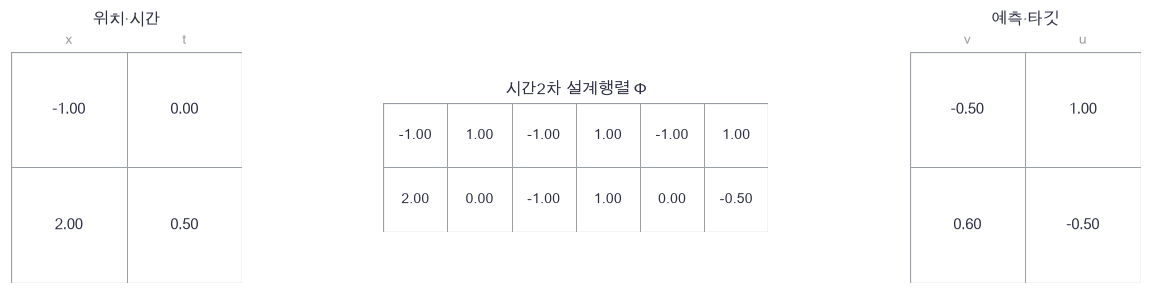

In [9]:
plot_specification(np.column_stack([spec_x,spec_t]),spec_design,spec_outputs)

🔍 **확인** · t=0이면 시간 특징은(1,−1,1), t=.5이면(1,0,−.5)입니다. θ의 앞 절반은 x의 계수, 뒤 절반은 위치에 무관한 이동을 정합니다.

In [10]:
def features(x,t,degree=2):
    """시간의 shifted Legendre P0,P1,P2와 x배를 붙인 선형 모형 설계행렬입니다."""
    assert degree in [0,2], '이 실험은 시간 없음0과 시간2차만 비교합니다'
    r=2*t-1
    basis=np.column_stack([np.ones_like(t),r,(3*r**2-1)/2])[:,:degree+1]
    return np.concatenate([x[:,None]*basis,basis],axis=1)

In [11]:
actual_design=features(spec_x,spec_t,2)
np.testing.assert_allclose(actual_design,[[-1,1,-1,1,-1,1],[2,0,-1,1,0,-.5]])  # 검산: 직접 전개한 기저
loop_prediction=np.zeros(2)
for i in range(2):
    for j in range(6):
        loop_prediction[i]+=actual_design[i,j]*spec_theta[j]
np.testing.assert_allclose(loop_prediction,actual_design@spec_theta)  # 검산: 반복문과 배열 연산
np.testing.assert_allclose(features(spec_x,spec_t,0),[[-1,1],[2,1]])  # 검산: 시간 제거 후보

### ✏️ 연습 2 · 행마다 예측하기

Φ:(N,K)와 θ:(K,)로 예측(N,)을 반환하세요.

In [12]:
def exercise_linear_velocity(Phi,theta):
    """행마다 예측하기의 핵심 계산입니다."""
    ### 구현할 내용: Φ:(N,K)와 θ:(K,)로 예측(N,)을 반환하세요.
    raise NotImplementedError
    return prediction

In [13]:
def check_linear_velocity(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.],[-1.,3.]]),np.array([2.,-.5])),[1.,-3.5])  # 검산: 특징 내적
    print("연습 2 통과")

run_check(check_linear_velocity,exercise_linear_velocity,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_linear_velocity: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
prediction = Phi@theta
```

</details>

## 🔑 3. 같은 구현을 믿기 전에 독립 기준을 붙입니다

**이 절에서 가져갈 것:** 미분 구현, 최적점, 논문 관계를 서로 다른 방법으로 확인합니다.

손실 곡선이 내려가도 부호·분모가 맞다는 보장은 없습니다. 작은 회귀에서 손계산·반복문·중심차분을 먼저 연결합니다.

$$g=\Phi^T(\Phi\theta-u)/N,\qquad H=\Phi^T\Phi/N.$$

> **용어** · **Hessian H**는 기울기의 θ 미분입니다. 이 이차 목적에서는 상수입니다. **기준해**는 학습 루프와 독립적으로 구한 최소제곱 해입니다. **수치 적분(quadrature)**은 점과 가중치로 적분을 근사하는 방법입니다.

아래 목적 함수는 중심차분으로 전체 θ를 검사합니다. Hessian도 기울기 중심차분과 대조합니다. 이후 최소제곱은 역행렬 대신 `lstsq`로 풀어 GD가 어디까지 갔는지 확인합니다. 이런 수치 검사는 수학 정리 전체의 증명과는 다릅니다.

In [14]:
check_design=np.array([[1.,0.],[1.,2.]])
check_target=np.array([1.,3.])
check_theta=np.array([.5,.5])
check_residual=check_design@check_theta-check_target
check_gradient=check_design.T@check_residual/2

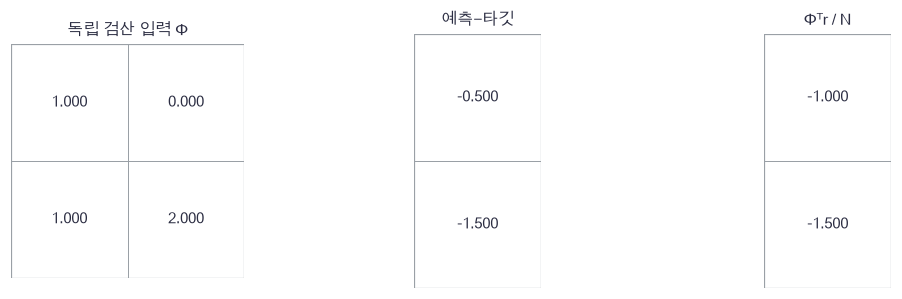

In [15]:
plot_independent_checks(check_design,check_residual,check_gradient)

🔍 **확인** · 잔차는(−.5,−1.5), 기울기는(−1,−1.5)입니다. 이 손계산은 아래 함수의 출력을 베껴 정답으로 둔 것이 아닙니다.

In [16]:
def regression_objective(design,target,theta):
    """반 제곱거리 평균·전체 θ 미분·Hessian을 반환합니다."""
    residual=design@theta-target
    return .5*np.mean(residual**2),design.T@residual/len(target),design.T@design/len(target)

In [17]:
def probe_objective():
    """손계산과 동일한 두 관측 회귀 목적을 θ로 미분합니다."""
    return regression_objective(check_design,check_target,check_theta)[0]

In [18]:
# 쓰는 것: check_design, check_target, check_theta (3절 손계산 셀)
loss,gradient,hessian=regression_objective(check_design,check_target,check_theta)
np.testing.assert_allclose(loss,.625)  # 검산: (.25+2.25)/(2*2)
np.testing.assert_allclose(gradient,[-1.,-1.5])  # 검산: 독립 손계산
np.testing.assert_allclose(gradient,numerical_gradient(probe_objective,check_theta),atol=1e-9)  # 검산: 전체 θ 중심차분
numeric_hessian=np.zeros((2,2))
for j in range(2):
    direction=np.eye(2)[j]*1e-5
    plus=regression_objective(check_design,check_target,check_theta+direction)[1]
    minus=regression_objective(check_design,check_target,check_theta-direction)[1]
    numeric_hessian[:,j]=(plus-minus)/2e-5
np.testing.assert_allclose(hessian,numeric_hessian,atol=1e-9)  # 검산: 기울기의 미분
assert np.min(np.linalg.eigvalsh(hessian))>0, '이 독립 입력에서는 목적이 엄격 볼록입니다'

📎 **논문 관계를 독립적으로 확인하기**

현재 Gaussian의 $a=1-.9t$, $s^2=a^2+.49t^2$, $c=.49t-.9a$를 쓰면 정확한 주변 속도는
$$v^*(x,t)=1.2+\frac{c}{s^2}(x-1.2t).$$
CFM과 FM의 차이는 $E[(u-v^*)^2]/2$이고 θ와 무관합니다. 이를 **학습에 쓴 유한 자료와 별개**로 적분합니다. x0와 정규화한 y에 각3점 Gauss–Hermite 적분을 사용합니다. 현재 선형 속도장의 손실·기울기는 이 두 Gaussian 변수의2차 다항식이라 이 축의 적분은 반올림 오차 내에서 정확합니다. 시간은16점 Gauss–Legendre이며32점과 비교해 근사 오차를 관찰합니다. 동일한 시간 노드에서는 두 목적 기울기의 등식이 각 시각마다 성립합니다.

> **코드** · `hermgauss(3)`는 가중치 exp(−z²)의 적분점이므로 표준 Gaussian에는 점을 √2배, 가중치를 √π로 나눕니다. `leggauss`의 구간[−1,1]을[0,1]로 옮기면서 가중치도2로 나눕니다. `meshgrid(indexing='ij')`는 세 독립 축의 모든 조합입니다.

In [19]:
def reference_velocity(x,t,minimum=.1):
    """원자료 Gaussian의 정확한 주변 속도, x와 t는 broadcast 가능한 배열입니다."""
    a=1-(1-minimum)*t
    variance=a*a+t*t*.7**2
    covariance=t*.7**2-(1-minimum)*a
    return 1.2+covariance/variance*(x-t*1.2)

In [20]:
def gaussian_quadrature(time_nodes=16,minimum=.1):
    """Gaussian 각3점·시간 Gauss-Legendre 적분의 경로점·타깃·가중치를 만듭니다."""
    nodes,weight=np.polynomial.hermite.hermgauss(3)
    z=np.sqrt(2)*nodes
    w=weight/np.sqrt(np.pi)
    tn,tw=np.polynomial.legendre.leggauss(time_nodes)
    time=(tn+1)/2
    time_weight=tw/2
    x0,z1,t=np.meshgrid(z,z,time,indexing='ij')
    weights=w[:,None,None]*w[None,:,None]*time_weight[None,None,:]
    y=1.2+.7*z1
    a=1-(1-minimum)*t
    return (a*x0+t*y).ravel(),t.ravel(),(y-(1-minimum)*x0).ravel(),weights.ravel()

In [21]:
def weighted_objective(design,target,theta,weights):
    """적분 가중치 합1인 목적과 θ 미분. Monte Carlo와 같은 식의 가중 합입니다."""
    residual=design@theta-target
    return .5*np.sum(weights*residual**2),design.T@(weights*residual)

In [22]:
# 쓰는 것: features (2절)
qx,qt,qu,qw=gaussian_quadrature(16)
qdesign=features(qx,qt,2)
qreference=reference_velocity(qx,qt)
qtheta=np.array([.1,-.3,.2,.6,.4,-.2])
cfm,cgrad=weighted_objective(qdesign,qu,qtheta,qw)
fm,fgrad=weighted_objective(qdesign,qreference,qtheta,qw)
constant=.5*np.sum(qw*(qu-qreference)**2)
np.testing.assert_allclose(qw.sum(),1.,atol=1e-12)  # 검산: 확률 적분 가중치
np.testing.assert_allclose(cgrad,fgrad,atol=1e-12)  # 검산: 원자료 Gaussian 기댓값 목적의 같은 미분
np.testing.assert_allclose(cfm-fm,constant,atol=1e-12)  # 검산: θ와 무관한 차이
other_theta=-qtheta
other_difference=weighted_objective(qdesign,qu,other_theta,qw)[0]-weighted_objective(qdesign,qreference,other_theta,qw)[0]
np.testing.assert_allclose(other_difference,constant,atol=1e-12)  # 검산: θ를 바꿔도 손실 차이 불변
qx32,qt32,qu32,qw32=gaussian_quadrature(32)
constant32=.5*np.sum(qw32*(qu32-reference_velocity(qx32,qt32))**2)
print('기울기 최대 차이',np.max(np.abs(cgrad-fgrad)),'· 잔여 적분16/32점',constant,constant32)

기울기 최대 차이 4.440892098500626e-16 · 잔여 적분16/32점 0.5001147452667816 0.5001147452667563


### ✏️ 연습 3 · 수치 검산할 기울기

평균 반 제곱오차의 θ 기울기를 구하세요.

In [23]:
def exercise_regression_gradient(Phi,theta,target):
    """수치 검산할 기울기의 핵심 계산입니다."""
    ### 구현할 내용: 평균 반 제곱오차의 θ 기울기를 구하세요.
    raise NotImplementedError
    return gradient

In [24]:
def check_regression_gradient(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,0.],[1.,2.]]),np.array([.5,.5]),np.array([1.,3.])),[-1.,-1.5])  # 검산: 독립 작은 회귀
    print("연습 3 통과")

run_check(check_regression_gradient,exercise_regression_gradient,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_regression_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = Phi.T@(Phi@theta-target)/len(target)
```

</details>

## 🔑 4. 한 요소를 바꾼 실제 학습과 기준해를 기록합니다

**이 절에서 가져갈 것:** 검증한 기울기로 실제 갱신하고 모든 반복·대조를 남깁니다.

시간 기저 유무만 실험 조건으로 바꾸되 파라미터 수도 함께 변한다는 점을 기록합니다. 두 후보는 같은 train·valid·test 쌍을 사용합니다. 3개 독립 학습 seed6301/6302/6303, 각 train512·valid128·test2048입니다. valid seed는+100, test seed는+200, 생성 seed는+300으로 독립 분리합니다. 각 쌍의 x0,y,t는 한 번 뽑아 고정합니다.

모든 모델은 θ=0, full-batch GD lr.15,600회입니다. 매60회 기록하고 valid로 checkpoint를 고르지 않습니다. 각 Hessian 최대 고유값에서 $.15\lambda_{max}<2$인지 확인하여 이 이차 문제에서의 GD 안정 조건을 검사합니다. 최종 모델을 test에 한 번 평가하며 성능을 본 뒤 seed나 예산을 변경하지 않습니다.

> **용어** · **제거 실험(ablation)**은 한 설계 요소를 빼거나 바꿔 차이를 관찰하는 비교입니다. **학습 최적화 오차**는 같은 유한 train 목적의 최소값까지 남은 차이입니다. 이는 원자료의 기대 손실이나 생성 품질과 다른 값입니다.

> **코드** · `np.linalg.lstsq(Phi,u,rcond=None)[0]`는 최소제곱 계수입니다. 정확한 역행렬을 직접 만들지 않습니다. `eigvalsh`는 대칭 Hessian의 고유값입니다.

In [25]:
plan=np.array([[512,128,2048,600,2],[512,128,2048,600,6]])

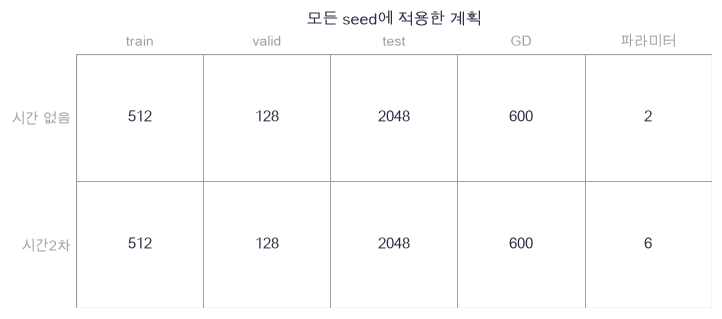

In [26]:
plot_reproduction_plan(plan)

🔍 **확인** · 학습 자료 수와 갱신 횟수는 같지만 모형 크기는 다릅니다. 3개 seed는 작은 반복 관찰이며 일반적인 알고리즘 우위를 입증하기에 충분한 표본이라고 가정하지 않습니다.

In [27]:
def gradient_descent(design,target,valid_design,valid_target,steps=600,lr=.15):
    """0초기값에서 고정 full-batch GD를 실제 수행합니다. valid로 선택하지 않습니다."""
    # 쓰는 것: regression_objective (3절)
    theta=np.zeros(design.shape[1])
    history=[]
    for step in range(steps+1):
        loss,gradient,_=regression_objective(design,target,theta)
        if step%60==0:
            history.append([step,loss,regression_objective(valid_design,valid_target,theta)[0]])
        if step<steps:
            theta-=lr*gradient
    return theta,np.array(history)

In [28]:
# 쓰는 것: features (2절) · make_pairs (1절) · regression_objective (3절)
seeds=[6301,6302,6303]
models=[]
histories=[]
records=[]
for seed in seeds:
    train=make_pairs(512,seed)
    valid=make_pairs(128,seed+100)
    test=make_pairs(2048,seed+200)
    for degree in [0,2]:
        design=features(*train[:2],degree)
        valid_design=features(*valid[:2],degree)
        theta,history=gradient_descent(design,train[2],valid_design,valid[2])
        least_squares=np.linalg.lstsq(design,train[2],rcond=None)[0]
        loss,gradient,hessian=regression_objective(design,train[2],theta)
        best_loss=regression_objective(design,train[2],least_squares)[0]
        assert .15*np.max(np.linalg.eigvalsh(hessian))<2, 'GD의 이차 목적 안정 조건이 필요합니다'
        assert loss-best_loss<2e-6, '고정600회 GD는 이 기준해 손실의2e-6 안에 도달해야 합니다'
        records.append([seed,degree,loss,best_loss,np.linalg.norm(gradient)])
        models.append((seed,degree,theta,test))
        histories.append(history)
print('seed·시간차수·GD손실·최소제곱손실·gradient norm')
print(np.array(records))

seed·시간차수·GD손실·최소제곱손실·gradient norm
[[6.30100000e+03 0.00000000e+00 5.93305679e-01 5.93305679e-01
  6.54608744e-16]
 [6.30100000e+03 2.00000000e+00 5.04551947e-01 5.04551888e-01
  9.15439372e-05]
 [6.30200000e+03 0.00000000e+00 6.00444133e-01 6.00444133e-01
  6.80315037e-16]
 [6.30200000e+03 2.00000000e+00 4.84315153e-01 4.84313841e-01
  3.85304845e-04]
 [6.30300000e+03 0.00000000e+00 5.93143221e-01 5.93143221e-01
  8.03361580e-16]
 [6.30300000e+03 2.00000000e+00 4.95469373e-01 4.95469270e-01
  1.20169212e-04]]


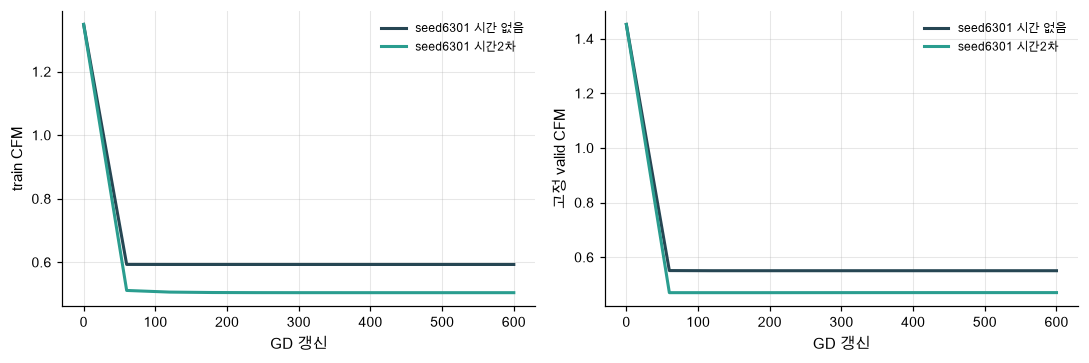

In [29]:
plot_reproduction_learning(histories[:2],["seed6301 시간 없음","seed6301 시간2차"])

🔍 **확인** · 그림은 미리 정한 첫 seed이며 다른 두 seed의 결과도 위 표에 모두 남습니다. GD와 최소제곱의 손실 차이가 작아도, 제한된 특징과 유한 자료로 생기는 모델 오차는 남습니다. 결과를 더 좋게 보이도록 seed를 고르지 않습니다.

### ✏️ 연습 4 · 기준해와의 차이

동일 train 목적에서 얻은 GD 손실과 최소제곱 손실의 차이를 반환하세요.

In [30]:
def exercise_optimization_gap(trained_loss,reference_loss):
    """기준해와의 차이의 핵심 계산입니다."""
    ### 구현할 내용: 동일 train 목적에서 얻은 GD 손실과 최소제곱 손실의 차이를 반환하세요.
    raise NotImplementedError
    return gap

In [31]:
def check_optimization_gap(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(.500001,.5),1e-6,atol=1e-12)  # 검산: 같은 목적끼리 비교
    print("연습 4 통과")

run_check(check_optimization_gap,exercise_optimization_gap,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_optimization_gap: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gap = trained_loss-reference_loss
```

</details>

## 🔑 5. 생성 그림과 근거의 한계를 함께 남깁니다

**이 절에서 가져갈 것:** 학습 수식이 맞는지와 생성 결과가 좋은지는 별도 증거로 판단합니다.

이번 Gaussian 주변 ODE의 정확한 경로는
$$x(t)=1.2t+\sqrt{(1-.9t)^2+.49t^2}\,x(0)$$
이고 끝점은 $1.2+\sqrt{.5}x(0)$입니다. 이는 실제 y와 독립 x0를 직선으로 이었던 학습용 쌍과 다른 경로입니다. 정확해를 미분하면 3절의 주변 속도가 나옵니다.

> **용어** · **짝지은 생성 비교**는 두 후보가 같은 초기 잡음의 같은 행에서 출발하게 하는 것입니다. **NFE**는 배치 벡터장 평가 횟수입니다. Heun32스텝은64회입니다. **격자 세분화 차이**는 Heun32와64의 결과 차이이며, 정확한 모델의 해를 모르는 경우 오차의 엄밀한 상한은 아닙니다.

모든 seed에서 같은 초기1024점을 두 모델에 넣고 Heun32(NFE64)로 생성합니다. 추가64스텝은 solver 진단용으로 따로 기록합니다. test 주변 속도 MSE, 정확 끝점과 평균 절대 거리, 세분화 차이를 함께 봅니다. 시간 특징을 추가해 속도 오차가 줄어도 유한 표본에서 생성 끝점 오차까지 매번 줄어든다고 단정하지 않습니다.

In [32]:
path_times=np.linspace(0,1,41)
path_start=np.array([-2.,-1.,0.,1.,2.])
path_scale=np.sqrt((1-.9*path_times)**2+.49*path_times**2)
exact_paths=1.2*path_times[:,None]+path_scale[:,None]*path_start

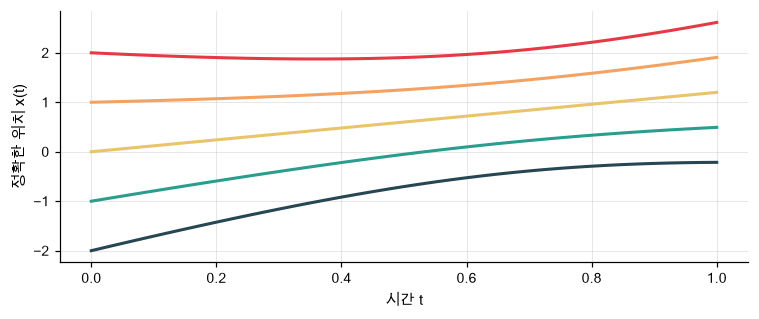

In [33]:
plot_exact_paths(path_times,exact_paths)

🔍 **확인** · 원래 관측 하나씩으로 직선 이동하는 그림이 아닙니다. 이 정확한 경로가 옮기는 분포의 평균과 분산이 원하는 주변 경로를 따릅니다.

In [34]:
def integrate_model(theta,degree,initial,steps=32):
    """학습한 1차원 속도장을 Heun으로0→1 적분합니다. NFE=2*steps입니다."""
    # 쓰는 것: features (2절)
    x=initial.copy()
    path=[x.copy()]
    h=1/steps
    for step in range(steps):
        t=np.full(len(x),step*h)
        first=features(x,t,degree)@theta
        second=features(x+h*first,t+h,degree)@theta
        x=x+h*(first+second)/2
        path.append(x.copy())
    return np.array(path)

In [35]:
# 쓰는 것: reference_velocity (3절)
probe_time=.37
delta=1e-5
times_pair=np.array([probe_time-delta,probe_time+delta])
scale_pair=np.sqrt((1-.9*times_pair)**2+.49*times_pair**2)
positions=1.2*times_pair[:,None]+scale_pair[:,None]*path_start
center_position=1.2*probe_time+np.sqrt((1-.9*probe_time)**2+.49*probe_time**2)*path_start
np.testing.assert_allclose((positions[1]-positions[0])/(2*delta),reference_velocity(center_position,probe_time),atol=1e-8)  # 검산: 정확 경로 미분 = 주변 속도
constant_theta=np.array([0.,1.2])
constant_path=integrate_model(constant_theta,0,path_start,7)
np.testing.assert_allclose(constant_path[-1],path_start+1.2,atol=1e-12)  # 검산: 일정한 속도는 정확히 이동

In [36]:
# 쓰는 것: features (2절) · models (4절) · reference_velocity (3절)
metrics=[]
sample_rows=[]
for seed,degree,theta,test in models:
    test_design=features(*test[:2],degree)
    velocity_error=np.mean((test_design@theta-reference_velocity(*test[:2]))**2)
    initial=np.random.default_rng(seed+300).normal(size=1024)
    coarse=integrate_model(theta,degree,initial,32)[-1]
    fine=integrate_model(theta,degree,initial,64)[-1]
    exact=1.2+np.sqrt(.5)*initial
    endpoint_error=np.mean(np.abs(coarse-exact))
    refinement=np.mean(np.abs(coarse-fine))
    metrics.append([velocity_error,endpoint_error,refinement])
    sample_rows.append((initial,coarse,exact))
metrics=np.array(metrics).reshape(3,2,3)
print('각 seed 행: 시간 없음/시간2차 · 열: 속도 MSE/끝점 MAE/세분화 차이')
print(metrics)
assert np.isfinite(metrics).all(), '성능의 높낮이 대신 유한값 규약을 검사합니다'

각 seed 행: 시간 없음/시간2차 · 열: 속도 MSE/끝점 MAE/세분화 차이
[[[2.06272341e-01 5.99125535e-02 2.10201760e-05]
  [1.76506040e-02 1.87163724e-02 1.01083020e-04]]

 [[2.09447199e-01 4.08874874e-02 1.56148040e-05]
  [8.94856435e-03 3.49600263e-02 1.81048920e-04]]

 [[2.10089009e-01 1.57100602e-02 1.70072318e-05]
  [1.15546711e-02 4.75115327e-02 1.46287023e-04]]]


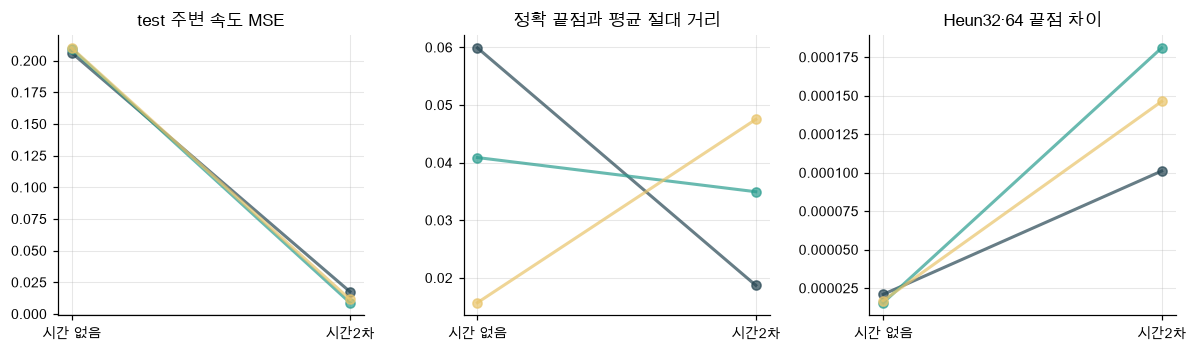

In [37]:
plot_paired_evidence(metrics,["시간 없음","시간2차"])

In [38]:
# 쓰는 것: sample_rows (5절)
np.testing.assert_array_equal(sample_rows[0][0],sample_rows[1][0])  # 검산: 첫 seed의 두 후보는 같은 출발점
order=np.argsort(sample_rows[0][0])
display_initial=sample_rows[0][0][order]
display_samples=[sample_rows[j][1][order] for j in [0,1]]
display_reference=sample_rows[0][2][order]

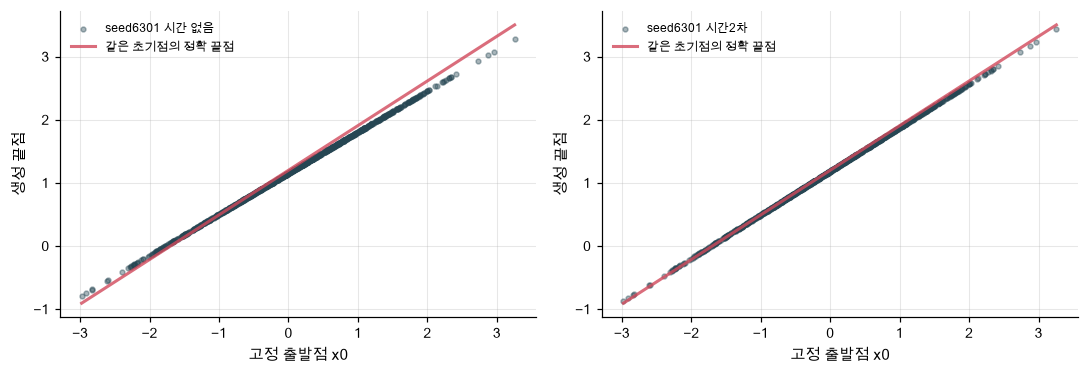

In [39]:
plot_paired_samples(display_initial,display_samples,display_reference,["seed6301 시간 없음","seed6301 시간2차"])

🔍 **확인** · 세 선은 각각 사전에 정한 독립 seed 하나입니다. 이 실행에서 시간2차의 속도 MSE는 모두 줄지만 끝점 오차가 모든 seed에서 줄지는 않습니다. 생성 그림은 첫 seed의 같은 초기1024점 전부입니다. 한 점씩 정확 끝점과 비교한 MAE는 이 Gaussian의 특정 coupling 진단이며 모든 생성 문제에 정답 대응이 주어지는 것은 아닙니다.

| 주장 | 실제 근거 | 여기서 결론 내릴 수 없는 것 |
|---|---|---|
| 구현 미분이 일치 | 손계산·중심차분·Hessian | 모든 입력·구조의 무오류 |
| 두 목적의 관계가 맞음 | Gaussian 적분·같은 gradient·θ 무관 차이 | 이 수치 예만으로 정리 전체 증명 |
| 실제 학습을 수행 | GD600회·train/valid·최소제곱 gap | 원논문의 대규모 성능 재현 |
| 시간 특징이 도움 | 3개 seed의 held-out 속도 MSE | 용량 효과와 시간 접근 효과 분리 |
| 생성 과정을 검산 | 같은 초기점·NFE64·정확 경로·세분화 | 모든 분포의 품질 우위나 likelihood 평가 |

다른 논문에서도 이 표의 **주장→계산→검산→한계**를 다시 채웁니다. 버전·자료 분할·seed·평균 분모·모델 크기·갱신 수·사용 루프는 본문 코드와 함께 보관합니다. 노트북의 저장 출력은 이 실행 기록이며 다시 실행한 관찰과 구분합니다.

### ✏️ 연습 5 · 짝지은 지표 차이

같은 seed 순서의 후보 A,B 지표에서 B−A 차이와 평균을 구하세요.

In [40]:
def exercise_paired_difference(A,B):
    """짝지은 지표 차이의 핵심 계산입니다."""
    ### 구현할 내용: 같은 seed 순서의 후보 A,B 지표에서 B−A 차이와 평균을 구하세요.
    raise NotImplementedError
    return difference,mean

In [41]:
def check_paired_difference(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    d,m=candidate(np.array([3.,2.,1.]),np.array([1.,1.,2.]))
    np.testing.assert_allclose(d,[-2.,-1.,1.])  # 검산: 유리하지 않은 seed도 유지
    np.testing.assert_allclose(m,-2/3)  # 검산: 동일 seed 차이 평균
    print("연습 5 통과")

run_check(check_paired_difference,exercise_paired_difference,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_paired_difference: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
difference = B-A
mean = difference.mean()
```

</details>

## ✏️ 전체 연결 연습 A–D

다른 논문을 골라도 평균 분모·shape·비용·검증 범위는 같은 방식으로 확인합니다.

### ✏️ 연습 A · Hessian 독립 계산

선형 회귀 평균 반 제곱오차의 Hessian을 반환하세요.

In [42]:
def exercise_hessian(Phi):
    """Hessian 독립 계산의 핵심 계산입니다."""
    ### 구현할 내용: 선형 회귀 평균 반 제곱오차의 Hessian을 반환하세요.
    raise NotImplementedError
    return H

In [43]:
def check_hessian(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,0.],[1.,2.]])),[[1.,1.],[1.,2.]])  # 검산: ΦᵀΦ/2
    print("연습 A 통과")

run_check(check_hessian,exercise_hessian,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_hessian: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
H = Phi.T@Phi/len(Phi)
```

</details>

### ✏️ 연습 B · 확률 적분 가중 평균

가중치 합1인 values의 평균을 계산하세요.

In [44]:
def exercise_weighted_mean(values,weights):
    """확률 적분 가중 평균의 핵심 계산입니다."""
    ### 구현할 내용: 가중치 합1인 values의 평균을 계산하세요.
    raise NotImplementedError
    return mean

In [45]:
def check_weighted_mean(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,3.]),np.array([.25,.75])),2.5)  # 검산: 표본 평균과 가중 평균 구별
    print("연습 B 통과")

run_check(check_weighted_mean,exercise_weighted_mean,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_weighted_mean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = np.sum(values*weights)
```

</details>

### ✏️ 연습 C · 학습 뒤 사용할 정확한 끝점

이 단원의 Gaussian 경로 정확 끝점을 반환하세요.

In [46]:
def exercise_exact_endpoint(x0):
    """학습 뒤 사용할 정확한 끝점의 핵심 계산입니다."""
    ### 구현할 내용: 이 단원의 Gaussian 경로 정확 끝점을 반환하세요.
    raise NotImplementedError
    return end

In [47]:
def check_exact_endpoint(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,0.,1.])),[1.2-np.sqrt(.5),1.2,1.2+np.sqrt(.5)])  # 검산: 끝점 분산.5
    print("연습 C 통과")

run_check(check_exact_endpoint,exercise_exact_endpoint,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_exact_endpoint: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
end = 1.2+np.sqrt(.5)*x0
```

</details>

### ✏️ 연습 D · 결과를 숨기지 않고 반복 기록하기

seed별 차이의 평균과 표본 SD를 반환하세요. 신뢰구간을 붙이지 않습니다.

In [48]:
def exercise_repeat_summary(differences):
    """결과를 숨기지 않고 반복 기록하기의 핵심 계산입니다."""
    ### 구현할 내용: seed별 차이의 평균과 표본 SD를 반환하세요. 신뢰구간을 붙이지 않습니다.
    raise NotImplementedError
    return mean,sd

In [49]:
def check_repeat_summary(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([-1.,0.,1.])),[0.,1.])  # 검산: 세 반복의 기술통계
    print("연습 D 통과")

run_check(check_repeat_summary,exercise_repeat_summary,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_repeat_summary: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
mean = differences.mean()
sd = differences.std(ddof=1)
```

</details>

📎 **준비도: 네 가지를 각각 확인하세요**

- **설명:** 논문의 주장·이번 축소 구현·새로 관측한 결과를 분리해 말할 수 있나요?
- **수식:** 확률 경로·목적·평균 축·전체 미분·사용 시 ODE를 빠짐없이 쓸 수 있나요?
- **구현:** 기호표를 배열 연산으로 옮기고 독립 기준해·중심차분·실제 학습을 연결할 수 있나요?
- **변형 검산:** 하나의 설정을 바꾸기 전에 분할·seed·비용·지표·판정 범위를 고정하고 모든 결과를 보고할 수 있나요?

**다음 논문에 적용할 순서:** 한 주장 선택 → 가정·shape·분모 명세 → 작은 독립 검산 → 실제 학습 → 같은 조건의 변형 → 결과와 한계 기록입니다. 미완성 요소는 명시하고 검증하지 않은 성능을 완료로 적지 않습니다.

**원자료:** [Lipman 등, Flow Matching for Generative Modeling, 3.2–4절](https://arxiv.org/html/2210.02747v2#S3.SS2). 이 단원은 기댓값 목적의 관계와 사용 절차를 작은 Gaussian 문제에서 직접 계산한 교육용 재현입니다. 원문 신경망과 이미지 성능표를 재현하지 않았습니다.